### this code calculates the raw distribution of first and last author pair

In [2]:
import pandas as pd
import numpy as np
import itertools
from tqdm import tqdm
import random

In [2]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all.head()

,ost_bk,cluster_id,cntry,role,year,dis
0,29768070,65683243.0,JPN,F,2008,51
1,29768070,79129017.0,JPN,M,2008,51
2,29768070,58951927.0,CHN,M,2008,51
3,29768070,9735544.0,JPN,M,2008,51
4,29768070,34120990.0,JPN,L,2008,51


### restructure the dataframe to cntry list format

In [3]:
pub_cntrys = pub_all.groupby(['ost_bk','year','dis'])['cntry'].apply(list).reset_index()

In [243]:
def generate_expectation(df, n):
    
    expect_res = pd.DataFrame()
    
    def random_shuffling(df):
        reshuffle_res = []
        for row in df.values:
            pub_id = row[0]
            year = row[1]
            cntrys = row[3]
            first, last = random.sample(cntrys, 2)
            reshuffle_res.append([pub_id, year, first, last])
            
        reshuffle_res = pd.DataFrame(reshuffle_res, columns=['ost_bk','year','first','last'])
        reshuffle_res = reshuffle_res.groupby(['year','first','last']).size().reset_index(name='exp')
        return reshuffle_res
    
    for _ in tqdm(range(n)):
        reshuffle_res = random_shuffling(df)
        expect_res = pd.concat([expect_res, reshuffle_res])
    
    expect_res = expect_res.groupby(['year','first','last'])['exp'].sum().reset_index()
    expect_res['exp'] = expect_res['exp']/n
    return expect_res

In [244]:
exp_df = generate_expectation(pub_cntrys, 100)

100%|█████████████████████████████████████████| 100/100 [23:08<00:00, 13.89s/it]


In [246]:
exp_df

,year,first,last,exp
0,2008,AFG,AFG,1.58
1,2008,AFG,CAN,0.17
2,2008,AFG,DEU,0.47
3,2008,AFG,EGY,0.19
4,2008,AFG,GBR,0.66
...,...,...,...,...
149568,2020,ZWE,VNM,0.02
149569,2020,ZWE,XKX,0.01
149570,2020,ZWE,ZAF,25.77
149571,2020,ZWE,ZMB,1.38


### calculate the occurrance from the real raw data

In [7]:
first_last_df = pub_all[pub_all.role!='M']
first_last_df = first_last_df.pivot(index=['ost_bk','year'], columns=['role'], values='cntry').reset_index()
raw_df = first_last_df.groupby(['year','F','L']).size().reset_index(name='raw')
raw_df = raw_df.rename(columns={'F':'first','L':'last'})
raw_df.head()

,year,first,last,raw
0,2008,AFG,GBR,1
1,2008,AFG,IND,1
2,2008,AGO,BRA,1
3,2008,ALB,ALB,2
4,2008,ALB,FRA,1


In [3]:
path = "../../data/dropbox/LaborDivision/data/deriveddata/intl_noalpha/authorship_reshuffle/first_last_pair.csv"
data = pd.read_csv(path)
data.head()

,year,first,last,raw,exp
0,2008,AFG,GBR,1.0,0.55
1,2008,AFG,IND,1.0,0.53
2,2008,AGO,BRA,1.0,0.59
3,2008,ALB,ALB,2.0,3.07
4,2008,ALB,FRA,1.0,1.07


In [28]:
group_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
group_df = pd.read_csv(group_path)
group_dict = dict(zip(group_df['Code'],group_df['class']))

In [29]:
data['first_class']=data['first'].map(group_dict)
data['last_class']=data['last'].map(group_dict)

In [31]:
test = data.copy()

In [32]:
test = test.groupby(['year','first_class','last_class']).agg({'raw':'sum','exp':'sum'}).reset_index()

In [36]:
test = test.sort_values(by=['first_class','last_class'])
test

,year,first_class,last_class,raw,exp
0,2008,Advanced,Advanced,90623.0,88673.49
16,2009,Advanced,Advanced,94729.0,92548.81
32,2010,Advanced,Advanced,99780.0,97151.65
48,2011,Advanced,Advanced,106441.0,103181.26
64,2012,Advanced,Advanced,113034.0,109132.44
...,...,...,...,...,...
143,2016,Proficient,Proficient,52508.0,45256.28
159,2017,Proficient,Proficient,58808.0,50396.98
175,2018,Proficient,Proficient,67402.0,58145.80
191,2019,Proficient,Proficient,80582.0,69870.97


In [41]:
test[140:200]

,year,first_class,last_class,raw,exp
170,2018,Lagging,Lagging,10439.0,10331.74
186,2019,Lagging,Lagging,13100.0,12887.92
202,2020,Lagging,Lagging,17411.0,17310.33
11,2008,Lagging,Proficient,536.0,487.84
27,2009,Lagging,Proficient,627.0,582.13
43,2010,Lagging,Proficient,775.0,729.58
59,2011,Lagging,Proficient,954.0,886.83
75,2012,Lagging,Proficient,980.0,995.93
91,2013,Lagging,Proficient,1109.0,1134.08
107,2014,Lagging,Proficient,1195.0,1314.37


In [24]:
b = data.groupby(['first','last','first_class','last_class']).agg({'raw':'sum','exp':'sum'}).reset_index()

In [25]:
b['diff'] = b['raw']-b['exp']

In [27]:
b[(b.first_class=='Lagging')&(b.last_class=='Developing')].sort_values(by='diff').head(30)

,first,last,first_class,last_class,raw,exp,diff
20784,VNM,IRN,Lagging,Developing,152.0,281.93,-129.93
20156,URY,ARG,Lagging,Developing,128.0,212.67,-84.67
9264,IRQ,IRN,Lagging,Developing,80.0,130.22,-50.22
18882,THA,IRN,Lagging,Developing,28.0,75.41,-47.41
20831,VNM,PAK,Lagging,Developing,39.0,85.78,-46.78
18933,THA,PAK,Lagging,Developing,41.0,80.61,-39.61
377,ARE,PAK,Lagging,Developing,93.0,131.25,-38.25
11344,LBY,EGY,Lagging,Developing,22.0,57.90,-35.90
16413,QAT,IRN,Lagging,Developing,24.0,59.55,-35.55
15078,OMN,IRN,Lagging,Developing,18.0,49.91,-31.91


In [124]:
a = test[(test.first_class=='Developing')&(test.last_class=='Developing')]

In [134]:
a[85:90]

,first,last,first_class,last_class,raw,exp
3731,COL,EGY,Developing,Developing,0.0,2.40
3747,COL,IDN,Developing,Developing,0.0,1.30
3750,COL,IRN,Developing,Developing,8.0,34.20
3762,COL,KWT,Developing,Developing,1.0,0.45
3768,COL,LVA,Developing,Developing,0.0,0.55


In [109]:
group_pair_agg = data.groupby(['first_class','last_class']).agg({'raw':'sum', 'exp':'sum'}).reset_index()
group_pair_agg['norm'] = np.log(group_pair_agg['raw']/group_pair_agg['exp'])

In [110]:
group_pair_agg

,first_class,last_class,raw,exp,norm
0,Advanced,Advanced,1644372.0,1585052.95,0.036741
1,Advanced,Developing,25101.0,52592.90,-0.739673
2,Advanced,Lagging,33798.0,63412.30,-0.629256
3,Advanced,Proficient,119140.0,281263.30,-0.858992
4,Developing,Advanced,74490.0,52574.85,0.348427
5,Developing,Developing,87561.0,89856.15,-0.025874
6,Developing,Lagging,14303.0,12715.40,0.117655
7,Developing,Proficient,24336.0,21746.05,0.112525
8,Lagging,Advanced,75834.0,63545.90,0.176784
9,Lagging,Developing,10913.0,12650.05,-0.147706


In [112]:
data[(data.first_class=='Developing')&(data.last_class=='Developing')]

,year,first,last,raw,exp,first_class,last_class
36,2008,ARG,ARG,461.0,372.10,Developing,Developing
40,2008,ARG,BOL,1.0,1.45,Developing,Developing
44,2008,ARG,CHL,20.0,23.55,Developing,Developing
46,2008,ARG,COL,6.0,8.35,Developing,Developing
61,2008,ARG,MEX,4.0,9.00,Developing,Developing
...,...,...,...,...,...,...,...
131275,2020,UZB,KWT,0.0,0.05,Developing,Developing
131278,2020,UZB,PAK,0.0,0.75,Developing,Developing
131290,2020,VEN,BOL,0.0,0.35,Developing,Developing
131293,2020,VEN,CRI,0.0,0.20,Developing,Developing


In [91]:
group_pair_agg

,first_class,last_class,raw,exp,norm
0,Advanced,Advanced,1644372,1584758.95,0.036926
1,Advanced,Developing,25098,51064.50,-0.710301
2,Advanced,Lagging,33755,57144.80,-0.526460
3,Advanced,Proficient,119140,279687.85,-0.853375
4,Developing,Advanced,74484,51904.45,0.361180
5,Developing,Developing,87553,89409.00,-0.020977
6,Developing,Lagging,14291,11562.65,0.211850
7,Developing,Proficient,24329,20995.55,0.147359
8,Lagging,Advanced,75793,60213.90,0.230103
9,Lagging,Developing,10890,11522.65,-0.056470


In [94]:
group_pair_year = data.groupby(['year','first_class','last_class']).agg({'raw':'sum','exp':'sum'}).reset_index()
group_pair_year['norm'] = np.log(group_pair_year['raw']/group_pair_year['exp'])

In [97]:
group_pair_year['group'] = group_pair_year['first_class']+"-"+group_pair_year['last_class']
group_pair_year.head()

,year,first_class,last_class,raw,exp,norm,group
0,2008,Advanced,Advanced,90623,88640.30,0.022121,Advanced-Advanced
1,2008,Advanced,Developing,1343,2276.15,-0.527580,Advanced-Developing
2,2008,Advanced,Lagging,1453,2150.70,-0.392163,Advanced-Lagging
3,2008,Advanced,Proficient,6607,11873.20,-0.586154,Advanced-Proficient
4,2008,Developing,Advanced,3402,2340.35,0.374063,Developing-Advanced


<Axes: xlabel='year', ylabel='norm'>

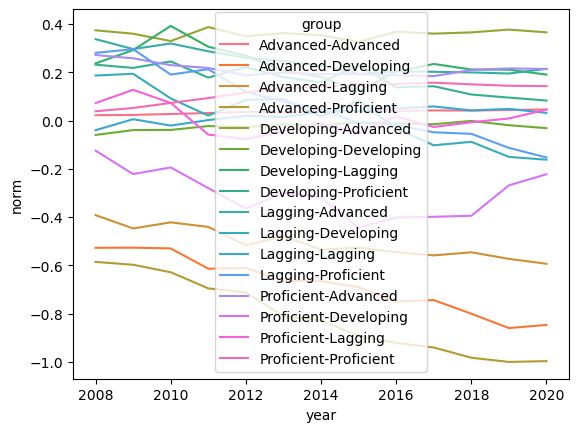

In [98]:
sns.lineplot(x='year', y='norm', hue='group', data=group_pair_year)

In [81]:
test=data.copy()
test=test.groupby(['first','last','first_class','last_class','group']).agg({'raw':'sum','exp':'sum'}).reset_index()
test=test[(test.raw!=0)&(test.exp!=0)]
test['norm']=np.log(test['raw']/test['exp'])
test=test[test['last']!=test['first']]

In [85]:
test[test['group']=='Advanced-Advanced'].sort_values(by='norm')

,first,last,first_class,last_class,group,raw,exp,norm
8451,ISL,TWN,Advanced,Advanced,Advanced-Advanced,1.0,10.15,-2.317474
8415,ISL,JPN,Advanced,Advanced,Advanced-Advanced,3.0,10.20,-1.223775
856,AUT,ISL,Advanced,Advanced,Advanced-Advanced,3.0,9.15,-1.115142
3038,CHE,TWN,Advanced,Advanced,Advanced-Advanced,22.0,65.35,-1.088715
4786,DNK,RUS,Advanced,Advanced,Advanced-Advanced,44.0,120.55,-1.007875
...,...,...,...,...,...,...,...,...
14945,RUS,FRA,Advanced,Advanced,Advanced-Advanced,2019.0,1519.85,0.283991
14932,RUS,DEU,Advanced,Advanced,Advanced-Advanced,3891.0,2903.20,0.292853
8036,IRL,ISL,Advanced,Advanced,Advanced-Advanced,11.0,8.20,0.293761
17478,TWN,CHE,Advanced,Advanced,Advanced-Advanced,94.0,66.75,0.342340


In [86]:
test.groupby(['first_class','last_class']).agg({'raw':'sum','exp':'sum'})

raw        exp
first_class last_class                     
Advanced    Advanced    513948.0  713661.10
            Developing   25101.0   52506.55
            Lagging      33796.0   62707.40
            Proficient  119140.0  281232.25
Developing  Advanced     74490.0   52535.55
            Developing    7883.0    8579.10
            Lagging      14302.0   12433.55
            Proficient   24336.0   21668.85
Lagging     Advanced     75831.0   63098.65
            Developing   10910.0   12410.85
            Lagging      16351.0   16458.25
            Proficient   18968.0   20745.90
Proficient  Advanced    345700.0  281167.20
            Developing   15244.0   21696.80
            Lagging      18883.0   20796.10
            Proficient   58116.0   70228.90

<Axes: xlabel='first_class', ylabel='norm'>

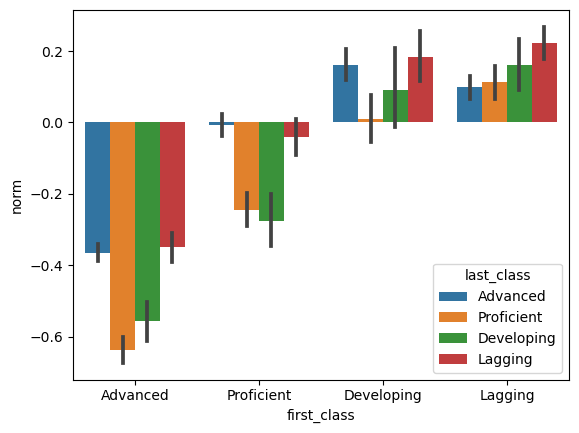

In [80]:
order = ['Advanced','Proficient','Developing','Lagging']
sns.barplot(x='first_class',y = 'norm',hue='last_class', data=test, order=order, hue_order=order)

In [ ]:
group_pair_agg['norm'] = group_pair_agg['raw']/group_pair_agg['exp']

In [9]:
df_first = pub_all[pub_all.role=='F'][['ost_bk','year','cntry']]
df_last = pub_all[pub_all.role=='L'][['ost_bk','year','cntry']]

In [185]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_st.csv'
stgroup_df=pd.read_csv(stgroup_path)
stgroup_df.head()

,Code,group
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [159]:
df_first = df_first.merge(stgroup_df, left_on='cntry', right_on='Code')
df_last = df_last.merge(stgroup_df, left_on='cntry', right_on='Code')

In [160]:
df_first.head()

,ost_bk,year,cntry,Code,ST
0,29768070,2008,JPN,JPN,Advanced
1,29768403,2008,JPN,JPN,Advanced
2,29768754,2008,JPN,JPN,Advanced
3,29769303,2008,JPN,JPN,Advanced
4,29769421,2008,JPN,JPN,Advanced


In [161]:
df_merged = pd.merge(df_first.drop(columns=['Code']), df_last.drop(columns=['Code']), on=['ost_bk','year'], suffixes=('_first','_last'))
df_merged.head()

,ost_bk,year,cntry_first,ST_first,cntry_last,ST_last
0,29768070,2008,JPN,Advanced,JPN,Advanced
1,29768403,2008,JPN,Advanced,JPN,Advanced
2,29768754,2008,JPN,Advanced,GBR,Advanced
3,29769303,2008,JPN,Advanced,JPN,Advanced
4,29769421,2008,JPN,Advanced,JPN,Advanced


In [162]:
df_merged['group'] = df_merged['ST_first']+"-"+df_merged['ST_last']
df_merged.head()

,ost_bk,year,cntry_first,ST_first,cntry_last,ST_last,group
0,29768070,2008,JPN,Advanced,JPN,Advanced,Advanced-Advanced
1,29768403,2008,JPN,Advanced,JPN,Advanced,Advanced-Advanced
2,29768754,2008,JPN,Advanced,GBR,Advanced,Advanced-Advanced
3,29769303,2008,JPN,Advanced,JPN,Advanced,Advanced-Advanced
4,29769421,2008,JPN,Advanced,JPN,Advanced,Advanced-Advanced


In [9]:
def reshuffle_author_order(df):

    result=[]
    for row in df.values:
        ost_bk, year, dis, cntrylist = row
        cntrylist = np.random.permutation(cntrylist)
        result.append([ost_bk, year, dis, cntrylist[0],'F'])
        result.append([ost_bk, year, dis, cntrylist[1], 'L'])
        
    result_df = pd.DataFrame(result, columns=['ost_bk','year','dis','cntry','role'])
    
    return result_df

In [10]:
def merge(reshuffled_df, role, stgroup_df):
    role_df = reshuffled_df[reshuffled_df['role']==role]
    role_df = role_df.merge(stgroup_df, left_on='cntry', right_on='Code')
    return role_df

In [50]:
n=20
grouped_pubs=pub_all.groupby(['ost_bk','year','dis'])['cntry'].apply(list).reset_index()

In [51]:
grouped_pubs.head()

,ost_bk,year,dis,cntry
0,29768070,2008,51,"[JPN, JPN, CHN, JPN, JPN]"
1,29768104,2008,61,"[USA, USA, USA, DEU]"
2,29768126,2008,18,"[ISL, ISL, USA, USA, ISL, USA, USA, ISL, ISL, ..."
3,29768150,2008,26,"[CHN, JPN, JPN, CHN, CHN, CHN]"
4,29768191,2008,44,"[USA, CHN, CHN, GBR, CHN, CHN]"


In [163]:
reshuffled_res = pd.DataFrame()
for _ in tqdm(range(20)):
    reshuffled_df = reshuffle_author_order(grouped_pubs)
    first_reshuffled = merge(reshuffled_df,'F',stgroup_df)
    last_reshuffled = merge(reshuffled_df, 'L', stgroup_df)
    merge_reshuffled = first_reshuffled[['ost_bk','year','cntry','ST']].merge(last_reshuffled[['ost_bk','year','cntry','ST']], on=['ost_bk','year'], suffixes=('_first','_last'))
    merge_reshuffled['group'] = merge_reshuffled['ST_first']+"-"+merge_reshuffled['ST_last']
    merge_reshuffled['cntrys'] = merge_reshuffled['cntry_first']+"-"+merge_reshuffled['cntry_last']
    reshuffled_res = pd.concat([reshuffled_res, merge_reshuffled[['ost_bk','year','cntrys','group']]])

100%|███████████████████████████████████████████| 20/20 [17:15<00:00, 51.80s/it]


In [164]:
reshuffled_res

,ost_bk,year,cntrys,group
0,29768070,2008,JPN-JPN,Advanced-Advanced
1,29768372,2008,JPN-ITA,Advanced-Advanced
2,29768754,2008,JPN-GBR,Advanced-Advanced
3,29769303,2008,JPN-USA,Advanced-Advanced
4,29769421,2008,JPN-AUS,Advanced-Advanced
...,...,...,...,...
3195984,101595802,2019,FRO-FRO,Lagging-Lagging
3195985,103087082,2020,FRO-FRO,Lagging-Lagging
3195986,104071122,2020,FRO-TUR,Lagging-Developing
3195987,104200078,2020,FRO-NLD,Lagging-Advanced


In [172]:
exp_df = reshuffled_res.groupby(['group']).size().reset_index(name='exp')
exp_df['exp'] = exp_df['exp']/20

In [173]:
raw_df = df_merged.groupby(['group']).size().reset_index(name='raw')

In [174]:
meta = raw_df.merge(exp_df, on=['group'])

In [175]:
meta['norm']=meta['raw']/meta['exp']

<Axes: xlabel='year', ylabel='norm'>

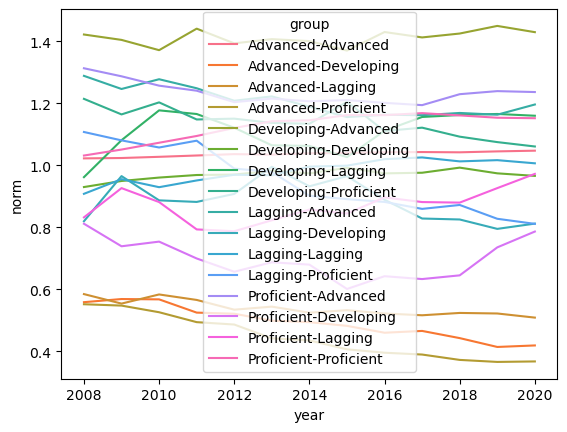

In [60]:
sns.lineplot(x='year', y='norm', hue='group', data=meta)

In [95]:
b = reshuffled_res[reshuffled_res.group=='Developing-Lagging']

In [97]:
b = b.groupby(['cntrys']).size().reset_index(name='exp')

In [98]:
b.sort_values(by='exp')

,cntrys,exp
303,COL-PSE,1
350,CRI-NPL,1
130,BEN-QAT,1
758,MEX-SLE,1
132,BEN-SAU,1
...,...,...
1019,TUR-SAU,7773
914,PAK-MYS,12320
564,IRN-MYS,19640
929,PAK-SAU,33121


In [129]:
rdf = df_merged[df_merged['group']=='Developing-Lagging']

In [130]:
rdf['cntrys'] = rdf['cntry_first']+"-"+rdf['cntry_last']

/tmp/ipykernel_261943/2584726077.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  rdf['cntrys'] = rdf['cntry_first']+"-"+rdf['cntry_last']


In [132]:
rdf[rdf.cntrys=='EGY-SAU']

,ost_bk,year,cntry_first,ST_first,cntry_last,ST_last,group,cntrys
2810498,29895896,2008,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2810541,30420452,2008,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2810552,30569522,2008,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2810560,30621341,2008,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2810590,31018599,2008,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
...,...,...,...,...,...,...,...,...
2825144,108540811,2018,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2825152,108586056,2020,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2825153,108587804,2020,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU
2825157,108634546,2016,EGY,Developing,SAU,Lagging,Developing-Lagging,EGY-SAU


In [133]:
rdf = rdf.groupby(['cntrys']).size().reset_index(name='raw')
rdf.head()

,cntrys,raw
0,ARG-ARE,2
1,ARG-BIH,1
2,ARG-DOM,1
3,ARG-ECU,20
4,ARG-ETH,2


In [134]:
test = rdf.merge(b, on='cntrys')
test['exp'] = test['exp']/20

In [145]:
test['norm'] = test['raw']-test['exp']

In [146]:
test = test.sort_values(by='norm')

<Axes: xlabel='norm', ylabel='Density'>

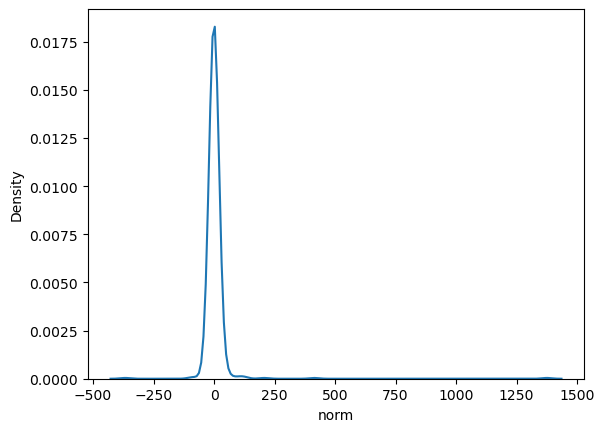

In [150]:
sns.kdeplot(x='norm', data=test)

In [155]:
stgroup_df.loc[stgroup_df['Code']=='MYS','ST']='Proficient'
stgroup_df.loc[stgroup_df['Code']=='VNM','ST']='Proficient'
stgroup_df.loc[stgroup_df['Code']=='SAU','ST']='Proficient'

In [157]:
stgroup_df[stgroup_df.ST=='Proficient']

,Code,ST
11,AZE,Proficient
16,BLR,Proficient
25,BRA,Proficient
27,BGR,Proficient
42,HRV,Proficient
43,CUB,Proficient
46,CZE,Proficient
58,EST,Proficient
71,GRC,Proficient
80,HUN,Proficient


In [152]:
test['raw'].sum()

14301

In [153]:
4301-2384

1917

In [38]:
test['cntrys'] = test['cntry_first']+"-"+test['cntry_last']
test['groups'] = test['ST_first']+"-"+test['ST_last']
test.head(2)

,ost_bk,year,cntry_first,ST_first,cntry_last,ST_last,cntrys,groups
0,29768070,2008,JPN,Advanced,JPN,Advanced,JPN-JPN,Advanced-Advanced
1,29768403,2008,JPN,Advanced,JPN,Advanced,JPN-JPN,Advanced-Advanced


In [49]:
a = test[test['groups']=='Developing-Lagging'].groupby(['cntrys']).size().reset_index(name='raw')

In [52]:
c = a.merge(b, on='cntrys')

In [58]:
c['norm'] = c['raw']/(c['exp']/20)

In [60]:
c.sort_values(by='raw', ascending=False).head(20)

,cntrys,raw,exp,norm
393,PAK-SAU,3031,33414,1.814210
151,EGY-SAU,2210,51965,0.850573
222,IRN-MYS,1396,19364,1.441851
383,PAK-MYS,743,12215,1.216537
243,IRN-VNM,488,5575,1.750673
179,IDN-MYS,426,6429,1.325245
445,TUR-SAU,384,7856,0.977597
233,IRN-SAU,259,3020,1.715232
237,IRN-THA,159,1534,2.073012
357,PAK-ARE,149,2630,1.133080


In [47]:
1182/20

59.1

In [52]:
test[(test['first']=='PAK')&(test['last']=='QAT')]

,first,last,raw,exp,norm
13676,PAK,QAT,98.0,51.35,1.908471


In [48]:
test = data.groupby(['first','last']).agg({'raw':'sum','exp':'sum'}).reset_index()
test['norm']=test['raw']/test['exp']

In [16]:
df_first_shuffled = reshuffled_df[reshuffled_df.role=='F']
df_last_shuffled = reshuffled_df[reshuffled_df.role=='L']
df_first_shuffled = df_first_shuffled.merge(stgroup_df, left_on='cntry', right_on='Code')
df_last_shuffled = df_last_shuffled.merge(stgroup_df, left_on='cntry', right_on='Code')

In [17]:
df_first_shuffled.head(2)

,id,year,dis,cntry,role,Code,ST
0,29768070,2008,51,JPN,F,JPN,Advanced
1,29768403,2008,39,JPN,F,JPN,Advanced


In [18]:
df_merged.head()

,ost_bk,year,ST_first,ST_last,group
0,29768070,2008,Advanced,Advanced,Advanced-Advanced
1,29768403,2008,Advanced,Advanced,Advanced-Advanced
2,29768754,2008,Advanced,Advanced,Advanced-Advanced
3,29769303,2008,Advanced,Advanced,Advanced-Advanced
4,29769421,2008,Advanced,Advanced,Advanced-Advanced


In [19]:
merged_shuffled = df_first_shuffled[['id','year','ST']].merge(df_last_shuffled[['id','year','ST']], on=['id','year'],suffixes=('_first','_last'))

In [21]:
merged_shuffled['group'] = merged_shuffled['ST_first']+"-"+merged_shuffled['ST_last']

In [36]:
df_merged.shape

(3195989, 5)

In [38]:
merged_shuffled.shape[0]/3195989

400.0

In [41]:
df_first_shuffled.shape[0]/3195989

20.0

In [42]:
df_first_shuffled

,id,year,dis,cntry,role,Code,ST
0,29768070,2008,51,JPN,F,JPN,Advanced
1,29768403,2008,39,JPN,F,JPN,Advanced
2,29768476,2008,78,JPN,F,JPN,Advanced
3,29769303,2008,82,JPN,F,JPN,Advanced
4,29769421,2008,12,JPN,F,JPN,Advanced
...,...,...,...,...,...,...,...
63919775,105246375,2016,73,TUV,F,TUV,Lagging
63919776,54476650,2018,33,TUV,F,TUV,Lagging
63919777,41405305,2014,73,TUV,F,TUV,Lagging
63919778,64536322,2017,64,TUV,F,TUV,Lagging


In [22]:
exp_df = merged_shuffled.groupby(['group']).size().reset_index(name='exp')

In [24]:
exp_df['exp'] = exp_df['exp']/20

In [26]:
exp_df.head(2)

,group,exp
0,Advanced-Advanced,33386417.10
1,Advanced-Developing,811638.85


In [29]:
raw_df = df_merged.groupby(['group']).size().reset_index(name='raw')
raw_df.head()

,group,raw
0,Advanced-Advanced,1644372
1,Advanced-Developing,25101
2,Advanced-Lagging,33798
3,Advanced-Proficient,119140
4,Developing-Advanced,74490


In [40]:
group_pair_agg

,first_class,last_class,raw,exp,norm
0,Advanced,Advanced,1644372.0,1585052.95,0.036741
1,Advanced,Developing,25101.0,52592.90,-0.739673
2,Advanced,Lagging,33798.0,63412.30,-0.629256
3,Advanced,Proficient,119140.0,281263.30,-0.858992
4,Developing,Advanced,74490.0,52574.85,0.348427
5,Developing,Developing,87561.0,89856.15,-0.025874
6,Developing,Lagging,14303.0,12715.40,0.117655
7,Developing,Proficient,24336.0,21746.05,0.112525
8,Lagging,Advanced,75834.0,63545.90,0.176784
9,Lagging,Developing,10913.0,12650.05,-0.147706


In [30]:
norm_df = raw_df.merge(exp_df, on='group')

In [31]:
norm_df

,group,raw,exp
0,Advanced-Advanced,1644372,33386417.10
1,Advanced-Developing,25101,811638.85
2,Advanced-Lagging,33798,1001040.90
3,Advanced-Proficient,119140,4450920.15
4,Developing-Advanced,74490,810507.80
5,Developing-Developing,87561,2194191.60
6,Developing-Lagging,14303,194494.65
7,Developing-Proficient,24336,338646.95
8,Lagging-Advanced,75834,1003409.65
9,Lagging-Developing,10913,194999.90


In [27]:
df_merged.head()

,ost_bk,year,ST_first,ST_last,group
0,29768070,2008,Advanced,Advanced,Advanced-Advanced
1,29768403,2008,Advanced,Advanced,Advanced-Advanced
2,29768754,2008,Advanced,Advanced,Advanced-Advanced
3,29769303,2008,Advanced,Advanced,Advanced-Advanced
4,29769421,2008,Advanced,Advanced,Advanced-Advanced


In [25]:
res_df.head()

,year,group,count
0,2008,Advanced-Advanced,90623
1,2008,Advanced-Developing,1343
2,2008,Advanced-Lagging,1458
3,2008,Advanced-Proficient,6607
4,2008,Developing-Advanced,3402


In [100]:
group_pair_year[group_pair_year['group']=='Advanced-Advanced']

,year,first_class,last_class,raw,exp,norm,group
0,2008,Advanced,Advanced,90623,88640.30,0.022121,Advanced-Advanced
16,2009,Advanced,Advanced,94729,92541.75,0.023360,Advanced-Advanced
32,2010,Advanced,Advanced,99780,97112.00,0.027103,Advanced-Advanced
48,2011,Advanced,Advanced,106441,103196.60,0.030955,Advanced-Advanced
64,2012,Advanced,Advanced,113034,109096.75,0.035454,Advanced-Advanced
80,2013,Advanced,Advanced,119707,115745.10,0.033657,Advanced-Advanced
96,2014,Advanced,Advanced,124437,119853.40,0.037530,Advanced-Advanced
112,2015,Advanced,Advanced,131533,126494.80,0.039057,Advanced-Advanced
128,2016,Advanced,Advanced,137091,131652.40,0.040480,Advanced-Advanced
144,2017,Advanced,Advanced,142682,136838.50,0.041817,Advanced-Advanced


In [106]:
test[test['group']=='Advanced-Advanced']

,first,last,first_class,last_class,group,raw,exp,norm
601,AUS,AUT,Advanced,Advanced,Advanced-Advanced,205.0,321.45,-0.449832
604,AUS,BEL,Advanced,Advanced,Advanced-Advanced,332.0,508.55,-0.426429
622,AUS,CAN,Advanced,Advanced,Advanced-Advanced,2347.0,2594.65,-0.100314
623,AUS,CHE,Advanced,Advanced,Advanced-Advanced,650.0,793.45,-0.199418
638,AUS,DEU,Advanced,Advanced,Advanced-Advanced,1814.0,2569.15,-0.348041
...,...,...,...,...,...,...,...,...
18224,USA,NLD,Advanced,Advanced,Advanced-Advanced,3752.0,6674.80,-0.576050
18225,USA,NOR,Advanced,Advanced,Advanced-Advanced,1218.0,2086.90,-0.538470
18242,USA,RUS,Advanced,Advanced,Advanced-Advanced,1632.0,2697.10,-0.502371
18259,USA,SWE,Advanced,Advanced,Advanced-Advanced,2617.0,4195.45,-0.471972
